# Denoising diffusion (U-Net)

A conditional DDPM: a ConvNeXt U-Net predicts the noise from $[x_t, y]$, where $y$ is concatenated as a
second channel. It was trained with a 1000-step cosine schedule and an L1 loss.
Weights: `weights/ddpm_conditional_unet_raw.pth`, the **raw** training weights (no EMA), like every other
learned method in Table 2.

Inference runs 250 reverse steps from Gaussian noise and draws 10 posterior samples per grid. **The 10
samples are averaged pixel-wise into the posterior mean, and the metrics are computed on that image.**

*Number of reverse steps.* The sampler was run with 250, 500 and 1000 steps. On 20 training grids
(every 1100th file of the training set, seed 0) the posterior mean reaches 55.98 dB with 250 steps but
only 39.88 dB with 500 steps, where samples diverge on half of the grids; with 1000 steps every sample
diverges. 250 steps are therefore used.
The sampler is stochastic. Its noise comes from a CPU random generator with a fixed seed, so it is the
same on every device. The Table-2 row uses seed 2; seeds 0 and 1 are printed to show the spread.
About 3.5 minutes on an RTX 3090.

**Evaluation protocol (all notebooks).** The 10 synthetic test grids (32 × 32 nodes, 50 m spacing) are
scaled to [-1, 1] per grid. PSNR, SSIM, relative error (RE) and RMSE are computed on the central 24 × 24
window and reported as mean ± standard deviation (ddof = 0) over the 10 grids. Networks run in full FP32
with deterministic cuDNN (set when `gravdc` is imported, see `gravdc/precision.py`).

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # make the gravdc package importable

import numpy as np
import torch

from gravdc import evaluate, format_summary, load_model, load_test_set, save_result, summarize
from gravdc.plotting import show_reconstruction
from gravdc.table2 import compare

DATA_DIR = "../data/test"
RESULTS_DIR = "../results"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.9.0+cu128


## Data
Observation: the ground-level field continued 100 m upward in a single step (zero padding to 36 × 36).

In [2]:
from gravdc import upward_continue

names, x = load_test_set(DATA_DIR)
x = x.to(device)
y = upward_continue(x, 100)
print(len(names), "grids:", names)
from gravdc.sampling import ddpm_sample

10 grids: ['data11.mat', 'data111.mat', 'data211.mat', 'data311.mat', 'data411.mat', 'data511.mat', 'data611.mat', 'data711.mat', 'data811.mat', 'data911.mat']


## Model and inference

In [3]:
SEEDS, SEED = [0, 1, 2], 2  # the Table-2 row uses seed 2
model = load_model("ddpm_unet", device)  # raw (non-EMA) weights
samples_by_seed = {s: ddpm_sample(model, y, timesteps=1000, steps=250, n_samples=10, seed=s) for s in SEEDS}
samples = samples_by_seed[SEED]  # (10 samples, 10 grids, 1, 32, 32)

## Metrics (posterior mean of the 10 samples)

In [4]:
def posterior_mean_metrics(samples):
    """Average the 10 samples of each grid pixel-wise (posterior mean), then score that one image."""
    return evaluate(x, samples.mean(0))


seed_summaries = {s: summarize(posterior_mean_metrics(samples_by_seed[s])) for s in SEEDS}
for s, summary in seed_summaries.items():
    print(f"seed {s}:  {format_summary(summary)}")
print()
per_image = posterior_mean_metrics(samples)
compare("Denoising diffusion (U-Net)", summarize(per_image))
print("\nper-grid PSNR (seed 2):", " ".join(f"{m['PSNR']:.2f}" for m in per_image))
save_result("Denoising diffusion (U-Net)", per_image, names, RESULTS_DIR, seed=SEED,
            aggregation="posterior mean of 10 samples",
            seed_summaries={str(s): v for s, v in seed_summaries.items()})

seed 0:  PSNR: 58.6030 ± 1.5464  SSIM: 0.9999 ± 0.0000  RE: 0.0035 ± 0.0004  RMSE: 0.0023 ± 0.0005
seed 1:  PSNR: 58.9006 ± 1.7356  SSIM: 0.9999 ± 0.0000  RE: 0.0034 ± 0.0005  RMSE: 0.0023 ± 0.0005
seed 2:  PSNR: 59.0080 ± 1.6162  SSIM: 0.9999 ± 0.0000  RE: 0.0034 ± 0.0004  RMSE: 0.0022 ± 0.0005

Denoising diffusion (U-Net)
  metric             this run              Table 2
  PSNR       59.0080 ± 1.6162     59.0080 ± 1.6162  ✓
  SSIM        0.9999 ± 0.0000      0.9999 ± 0.0000  ✓
  RE          0.0034 ± 0.0004      0.0034 ± 0.0004  ✓
  RMSE        0.0022 ± 0.0005      0.0022 ± 0.0005  ✓

per-grid PSNR (seed 2): 60.63 55.96 57.88 59.70 56.46 60.52 59.79 58.99 60.71 59.44


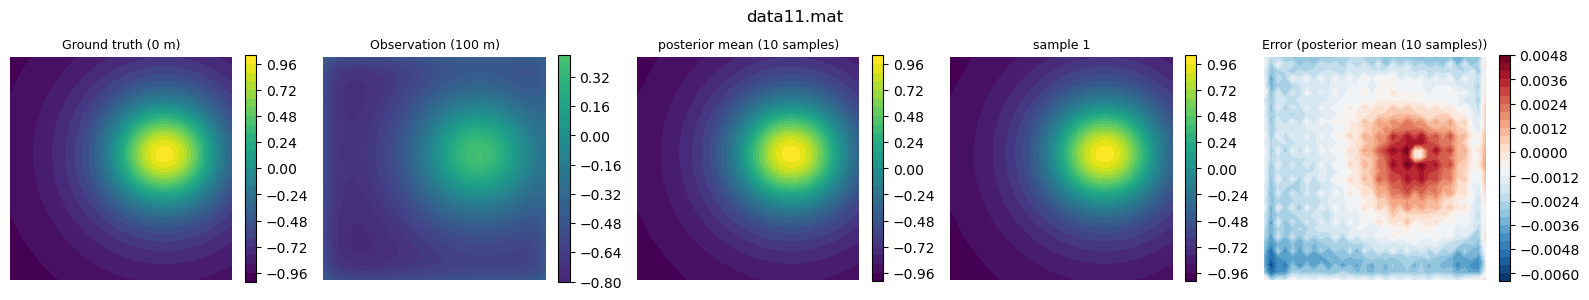

In [5]:
k = 0
show_reconstruction(x[k], y[k], {"posterior mean (10 samples)": samples[:, k].mean(0), "sample 1": samples[0, k]}, title=names[k])